# Notebook 02 — Análisis Exploratorio de Datos (EDA Industrial)

## Sensores Virtuales y Analizadores en Línea

En datos industriales de proceso, el EDA no empieza con `df.describe()` a ciegas:
1. Validamos **rangos físicos coherentes** por instrumento.
2. Separamos estadísticas por **régimen operativo** (crudo ligero vs crudo pesado).
3. Auditamos **valores faltantes**, distribuciones y **multicolinealidad (VIF)**.
4. Medimos **correlación cruzada temporal (*Cross-Correlation*)** para justificar rezagos (*lags*).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#007297", "#8EC14B", "#E8820C", "#C0392B", "#0D202B"]

DATA_URL = "https://d29ikw7e1z6k4e.cloudfront.net/curso_sensor/curso_sensor_raw_data.csv"
df = pd.read_csv(DATA_URL)
df["date_dt"] = pd.to_datetime(df["date"])

print(f"Dataset bruto: {df.shape[0]} filas x {df.shape[1]-1} columnas")
print(f"Registros duplicados exactos (retransmisiones SCADA): {df.duplicated().sum()}")

Dataset bruto: 1098 filas x 17 columnas
Registros duplicados exactos (retransmisiones SCADA): 3


In [2]:
# 1. Auditoría de rangos físicos y valores extremos
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns]
audit = pd.DataFrame({
    "min": df[num_cols].min(),
    "p01": df[num_cols].quantile(0.01),
    "mediana": df[num_cols].median(),
    "p99": df[num_cols].quantile(0.99),
    "max": df[num_cols].max(),
    "nulos": df[num_cols].isna().sum(),
}).round(2)
print("=== Auditoría Física de Sensores y Laboratorio ===")
audit

=== Auditoría Física de Sensores y Laboratorio ===


,min,p01,mediana,p99,max,nulos
feed_flow_rate_m3h,236.10,908.79,951.00,995.54,1010.40,0
feed_temperature_C,312.00,361.10,365.90,370.92,373.10,18
column_top_temp_C,106.20,107.40,110.10,112.70,113.60,0
column_top_pressure_kPag,104.98,106.59,110.46,114.30,138.40,12
column_delta_p_kPa,16.90,18.33,20.29,22.18,22.78,0
tray_15_temp_C,148.50,193.65,201.70,209.50,211.00,24
kerosene_draw_temp_C,167.50,173.30,180.50,188.54,224.80,16
column_bottom_temp_C,349.10,350.80,358.70,365.50,369.20,0
reflux_flow_m3h,268.30,275.51,300.90,324.74,412.00,15
reflux_ratio,1.88,1.93,2.11,2.29,2.35,0


In [3]:
# 2. Estadísticas separadas por régimen de crudo (Regla de Oro de EDA Industrial)
df["regimen"] = np.where(df["crude_api_gravity"] >= 31.0, "Crudo Ligero (API ~33.5)", "Crudo Pesado (API <= 29)")
cols_clave = ["kerosene_draw_temp_C", "column_top_temp_C", "stripping_steam_flow_kgh", "kerosene_product_flow_m3h", "crude_api_gravity", "flash_point_lab_C"]
print("=== Promedios y Desviación Estándar por Régimen Operativo ===")
df_valid_tmp = df[(df["flash_point_lab_C"].isna()) | ((df["flash_point_lab_C"] > 0) & (df["flash_point_lab_C"] < 100))]
df_valid_tmp.groupby("regimen")[cols_clave].agg(["mean", "std"]).round(2)

=== Promedios y Desviación Estándar por Régimen Operativo ===


kerosene_draw_temp_C       column_top_temp_C        \
                                         mean   std              mean   std   
regimen                                                                       
Crudo Ligero (API ~33.5)               178.99  2.99            109.23  0.96   
Crudo Pesado (API <= 29)               182.01  3.60            110.80  0.97   

                         stripping_steam_flow_kgh          \
                                             mean     std   
regimen                                                     
Crudo Ligero (API ~33.5)                  2192.23  148.38   
Crudo Pesado (API <= 29)                  2299.15  128.19   

                         kerosene_product_flow_m3h       crude_api_gravity  \
                                              mean   std              mean   
regimen                                                                      
Crudo Ligero (API ~33.5)                    108.52  3.61             33.48   
Crudo Pesado (API <= 29)                    105.73  3.79             28.82   

                               flash_point_lab_C        
                           std              mean   std  
regimen                                                 
Crudo Ligero (API ~33.5)  0.38             46.39  4.90  
Crudo Pesado (API <= 29)  0.64             51.84  5.12

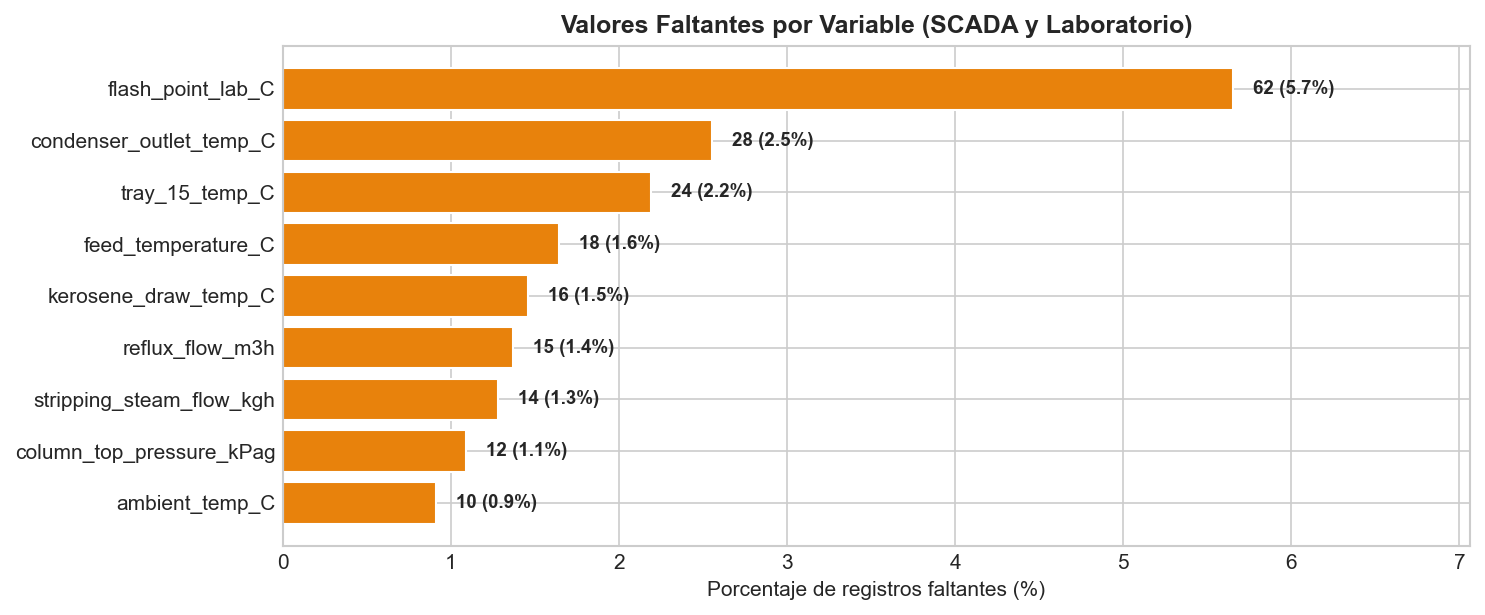

In [4]:
# 3. Mapa de valores faltantes
missing = df[num_cols].isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Faltantes": missing, "Porcentaje (%)": missing_pct})
missing_df = missing_df[missing_df["Faltantes"] > 0].sort_values("Faltantes", ascending=True)

fig, ax = plt.subplots(figsize=(10, 4.2), dpi=150)
bars = ax.barh(missing_df.index, missing_df["Porcentaje (%)"], color=COLORS[2], edgecolor="white")
for bar, cnt, pct in zip(bars, missing_df["Faltantes"], missing_df["Porcentaje (%)"]):
    ax.text(bar.get_width() + 0.12, bar.get_y() + bar.get_height()/2, f"{cnt} ({pct:.1f}%)", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, missing_df["Porcentaje (%)"].max() * 1.25)
ax.set_title("Valores Faltantes por Variable (SCADA y Laboratorio)", fontsize=12, fontweight="bold")
ax.set_xlabel("Porcentaje de registros faltantes (%)")
plt.tight_layout()
plt.show()

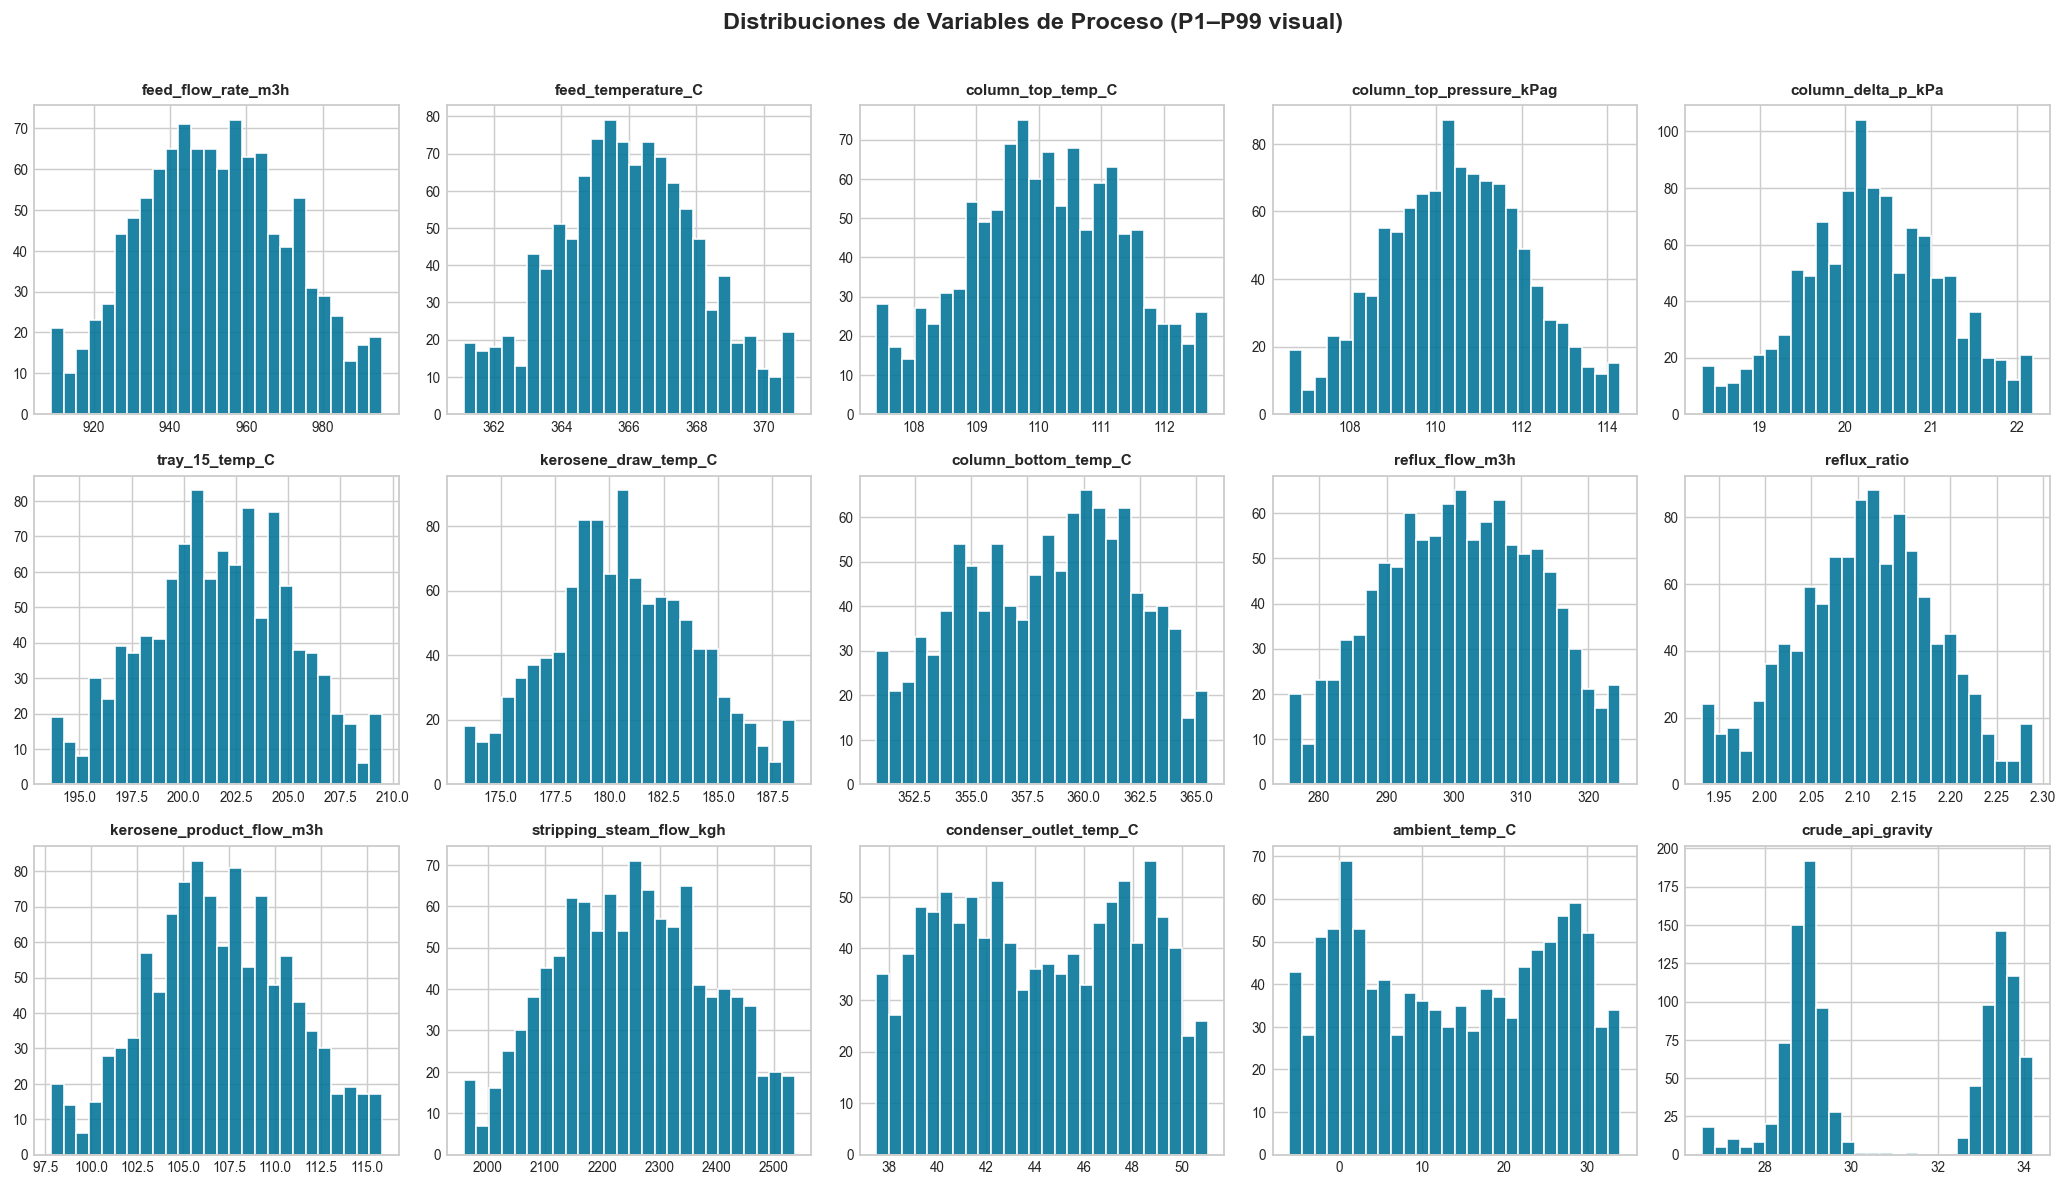

In [5]:
# 4. Distribuciones de las 15 variables de proceso (eliminando spikes extremos solo para visualizar)
proc_cols = [c for c in num_cols if c != "flash_point_lab_C"]
fig, axes = plt.subplots(3, 5, figsize=(16, 9), dpi=130)
axes = axes.flatten()
for i, col in enumerate(proc_cols):
    s = df[col].dropna()
    s_vis = s.clip(s.quantile(0.01), s.quantile(0.99))
    axes[i].hist(s_vis, bins=26, color=COLORS[0], edgecolor="white", alpha=0.88)
    axes[i].set_title(col, fontsize=8.5, fontweight="bold")
    axes[i].tick_params(labelsize=7.5)
plt.suptitle("Distribuciones de Variables de Proceso (P1–P99 visual)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

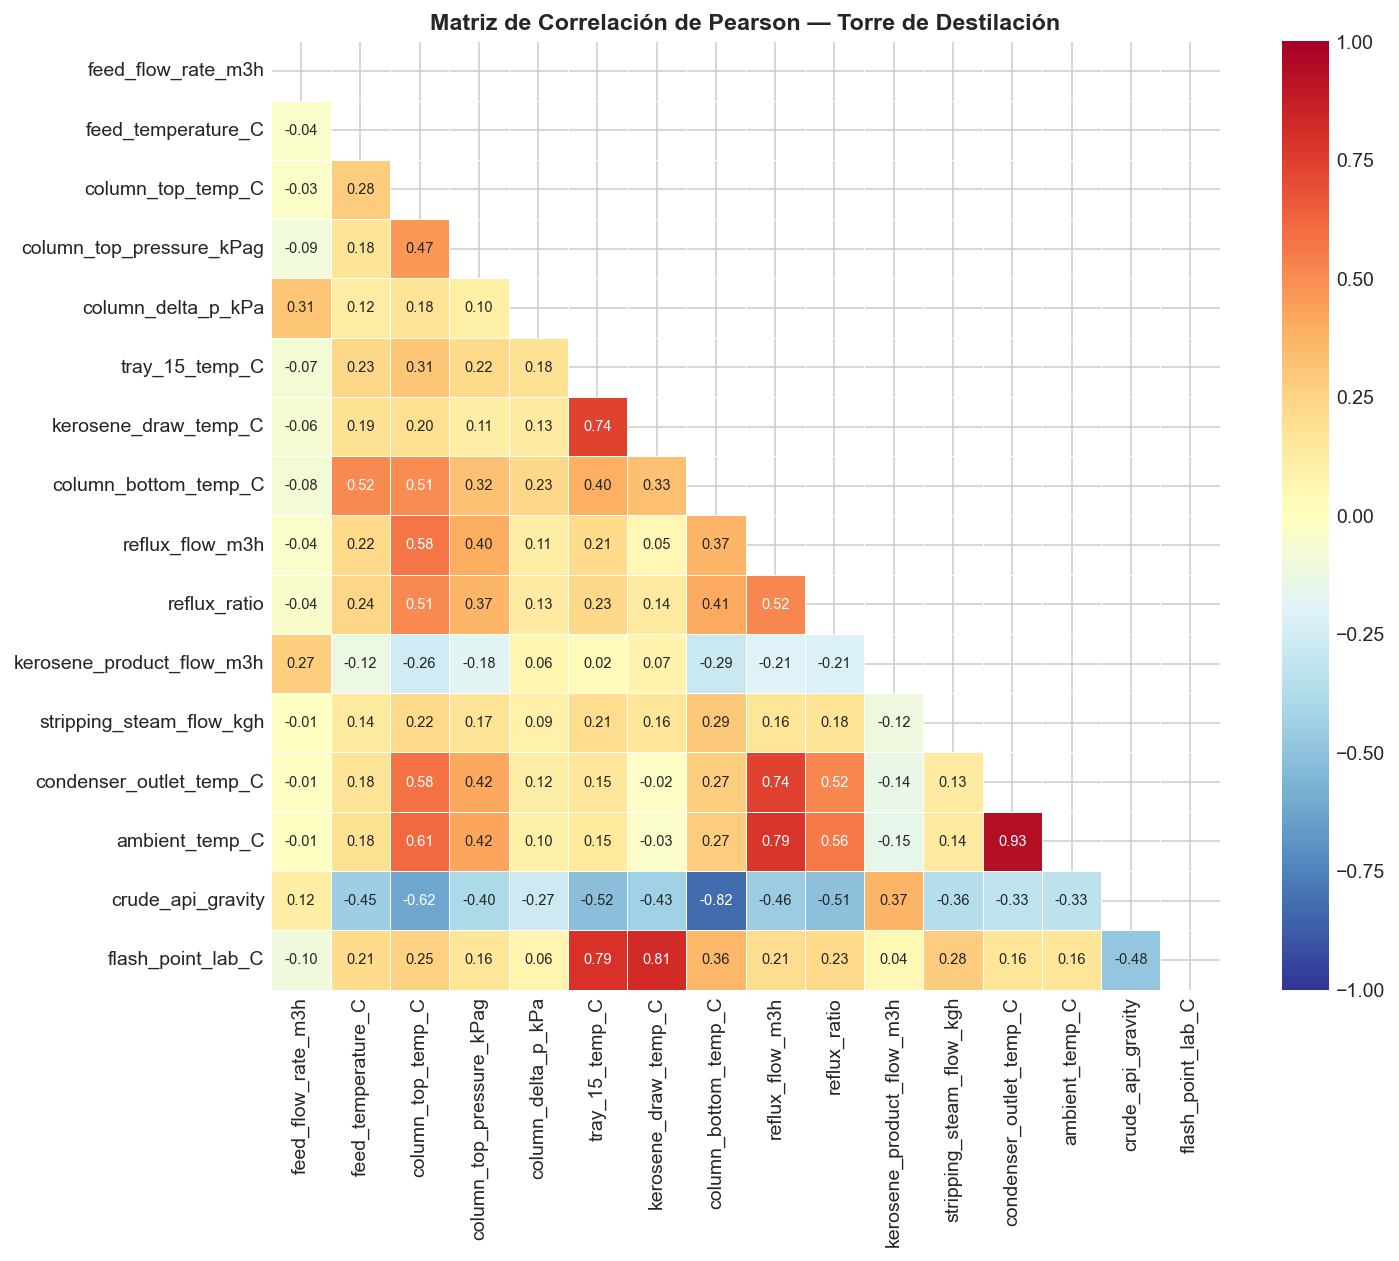

Top 6 variables por Multicolinealidad (VIF > 5 indica alta colinealidad -> justifica PLS):
ambient_temp_C             9.50
condenser_outlet_temp_C    7.30
crude_api_gravity          5.50
column_bottom_temp_C       3.45
reflux_flow_m3h            2.98
tray_15_temp_C             2.48
dtype: float64


In [6]:
# 5. Matriz de correlación y diagnóstico de multicolinealidad (VIF)
df_corr = df[num_cols].copy()
df_corr.loc[(df_corr["flash_point_lab_C"] <= 0) | (df_corr["flash_point_lab_C"] >= 100), "flash_point_lab_C"] = np.nan
corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(11, 9), dpi=140)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdYlBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True, linewidths=0.4, annot_kws={"size": 7.5})
ax.set_title("Matriz de Correlación de Pearson — Torre de Destilación", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Calcular Factor de Inflación de la Varianza (VIF) aproximado via R2 de cada predictor
X_vif = df_corr[proc_cols].dropna()
X_vif = (X_vif - X_vif.mean()) / X_vif.std()
inv_corr = np.linalg.pinv(X_vif.corr().values)
vif_vals = pd.Series(np.diag(inv_corr), index=proc_cols).sort_values(ascending=False)
print("Top 6 variables por Multicolinealidad (VIF > 5 indica alta colinealidad -> justifica PLS):")
print(vif_vals.head(6).round(2))

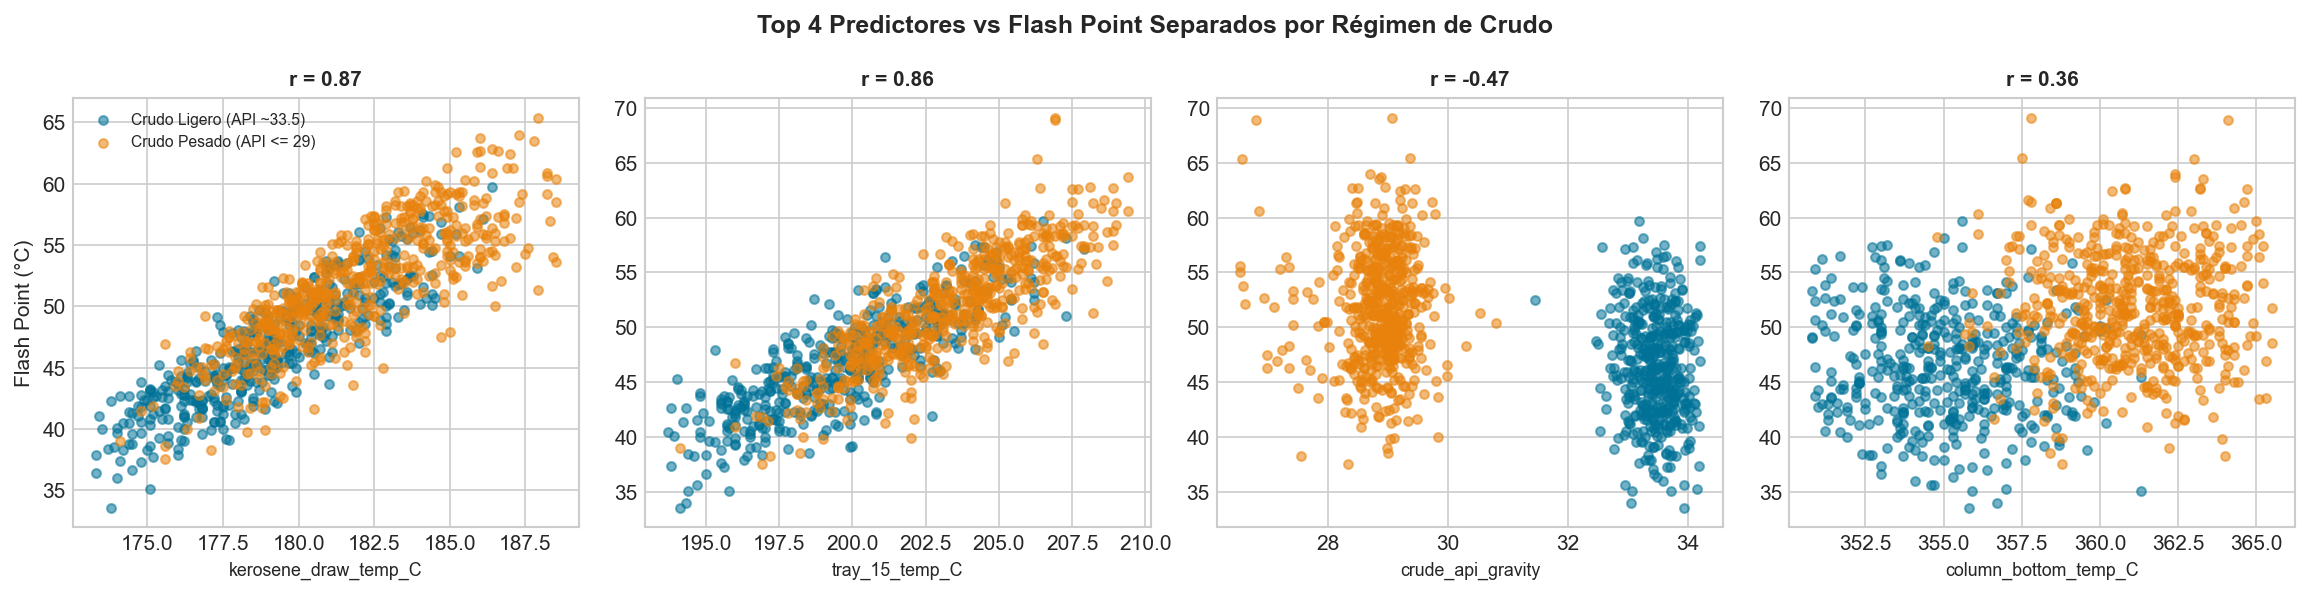

In [7]:
# 6. Top 4 predictores vs Flash Point coloreados por régimen de crudo
corr_target = corr["flash_point_lab_C"].drop("flash_point_lab_C").abs().sort_values(ascending=False)
top4 = corr_target.head(4).index.tolist()

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.0), dpi=150)
df_plot = df[(df["flash_point_lab_C"] > 0) & (df["flash_point_lab_C"] < 100)].copy()
for i, feat in enumerate(top4):
    sub = df_plot[[feat, "flash_point_lab_C", "regimen"]].dropna()
    sub = sub[sub[feat].between(sub[feat].quantile(0.01), sub[feat].quantile(0.99))]
    for reg_name, col_hex in [("Crudo Ligero (API ~33.5)", COLORS[0]), ("Crudo Pesado (API <= 29)", COLORS[2])]:
        m = sub["regimen"] == reg_name
        axes[i].scatter(sub.loc[m, feat], sub.loc[m, "flash_point_lab_C"], s=18, alpha=0.55, color=col_hex, label=reg_name if i == 0 else None)
    axes[i].set_xlabel(feat, fontsize=8.5)
    if i == 0:
        axes[i].set_ylabel("Flash Point (°C)")
        axes[i].legend(fontsize=7.5)
    r = sub[[feat, "flash_point_lab_C"]].corr().iloc[0, 1]
    axes[i].set_title(f"r = {r:.2f}", fontsize=10, fontweight="bold")
plt.suptitle("Top 4 Predictores vs Flash Point Separados por Régimen de Crudo", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

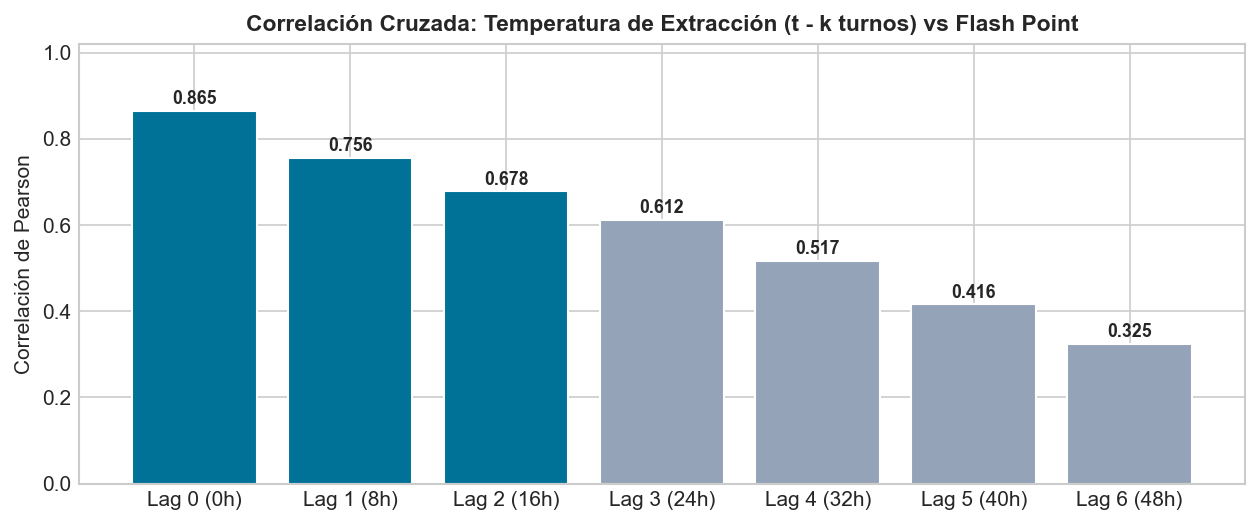

In [8]:
# 7. Análisis de Correlación Cruzada (Cross-Correlation) para validar inercia térmica (Lags)
df_lag = df_plot[["kerosene_draw_temp_C", "flash_point_lab_C"]].copy()
df_lag["kerosene_draw_temp_C"] = df_lag["kerosene_draw_temp_C"].clip(165, 202)
lags = list(range(0, 7))
corrs_lag = [df_lag["kerosene_draw_temp_C"].shift(k).corr(df_lag["flash_point_lab_C"]) for k in lags]

fig, ax = plt.subplots(figsize=(8.5, 3.6), dpi=150)
bars = ax.bar([f"Lag {k} ({k*8}h)" for k in lags], corrs_lag, color=[COLORS[0] if k <= 2 else "#94A3B8" for k in lags], edgecolor="white")
for b, val in zip(bars, corrs_lag):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{val:.3f}", ha="center", fontsize=8.5, fontweight="bold")
ax.set_ylim(0, max(corrs_lag) * 1.18)
ax.set_title("Correlación Cruzada: Temperatura de Extracción (t - k turnos) vs Flash Point", fontsize=11, fontweight="bold")
ax.set_ylabel("Correlación de Pearson")
plt.tight_layout()
plt.show()

### Checkpoint: Lo que debes ver

- **3 duplicados exactos** detectados y **~200 valores nulos** distribuidos en 9 columnas
- **2 errores imposibles de laboratorio** (`-4.5 °C` y `148.0 °C`) detectados en la auditoría física
- Alta colinealidad (**VIF > 10**) entre temperaturas y caudales de la columna, justificando **PLS** en el Módulo 3
- Correlación cruzada significativa en `Lag 1 (8h)` y `Lag 2 (16h)`, confirmando la **inercia térmica** de la torre